# Figures for gravity.md

*David Munro*


In [ ]:
# General imports and utility functions

from numpy import (array, asarray, pi, sin, cos, sqrt, linspace, zeros,
    digitize, maximum, minimum, arange)


# Two argument sinc for when sin(x) has already been computed.
def sinc2(x, sinx):
    """return sinx/x, assuming sinx = sin(x)"""
    x = asarray(x, float)  # incorrect if x is complex
    sinx = asarray(sinx, float)
    zero = (x == 0.) + 0.  # 1.0 where x == 0, else 0.0
    return (zero + sinx) / (zero + x)  # sinx==x exactly if abs(x) < 1e-8


# polyconic function is for reference only - essentially this is case of
# ncone=infinity in the cone_map function below
def polyconic(phi, theta, full=False):
    """Polyconic mapping from (lon, lat) in radians to (x, y)"""
    phi, theta = asarray(phi, float), asarray(theta, float)
    sint, cost = sin(theta), cos(theta)
    fphi = 0.5 * sint * phi
    sinf, cosf = sin(fphi), cos(fphi)
    sincf = sinc2(fphi, sinf)
    r = phi * cost * sincf
    x, y = r * cosf, theta + r * sinf
    if not full:
        return x, y
    # Also compute normalized direction from (x, y) to center of lat circle,
    # may be useful for computing (x, y) in unrolled strips.
    u = (1. - 2. * sinf * cosf) * cost
    v = -(theta * sint + 2. * sinf**2 * cost)
    w = sqrt(u**2 + v**2)
    u /= w
    v /= w
    return x, y, u, v


def get_cones(ncone=19):
    """return (lat, y, f, u, v) for ncone inscribed cones

    These divide globe into ncone cones spanning equal latitudes plus two
    polar disks with diameter equal to the common width of the latitude strips.
    That common width is dlat = 180/(ncone-1) degrees.  The first and last
    "cones" are always the polar disks.  The middle "cone" is a cylinder if
    ncone is odd (recommended).  The default ncone=19 produces 10 degree
    conical strips.

    Returns
    -------
    lat : ndarray shape(ncone+1)
        latitudes (radians) where cones are joined, which are latitude circles
        on the surface of the globe.
    y : ndarray shape(ncone+1)
        vertical coordinates at x=0 in unrolled flattened mapping corresponding
        to lat
    f : ndarray shape(ncone)
        fraction of full circle for unrolled latitude arc
    u : ndarray shape(ncone+1)
        coordinate normal to (x, y) plane corresponding to lat on surface of
        globe, that is, the 3D radius of the longitude circle
    v : ndarray shape(ncone+1)
        y coordinate of joint between cones on globe (y runs from south to
        north pole)
    """
    latmax = 0.5*(pi + pi/(ncone - 1))
    lat = linspace(-latmax, latmax, ncone + 1)
    v = sin(lat)
    lat[0], lat[-1] = -0.5*pi, 0.5*pi
    u = cos(lat)
    y = 0.*lat
    y[1:] = sqrt((u[1:] - u[:-1])**2 + (v[1:] - v[:-1])**2).cumsum()
    y -= y.mean()
    f = (u[:-1] - u[1:]) / (y[1:] - y[:-1])
    return lat, y, f, u, v


def cone_edges(ncone=19, nlon=360):
    """return edges for ncone conical strips at nlon+1 longitudes on (-180,180)

    Returns
    -------
    x : ndarray shape(ncone, 2, nlon+1)
        x coordinates of unrolled cone edges, x[:, 0] lower edge of cone i,
        x[: 1] upper edge of cone i
    y : ndarray shape(ncone, 2, nlon+1)
        y coordinates of unrolled cone edges
    """
    lat, y0, f, u, v = get_cones(ncone)
    phi = linspace(-pi, pi, nlon+1)
    x = zeros((ncone, 2, nlon+1))
    hfphi = 0.5 * f[:, None] * phi  # shape(ncone, nlon+1)
    hfphi = hfphi[:, None]  # shape(ncone, 1, nlon+1)
    shfphi = sin(hfphi)
    sinc_hfphi = sinc2(hfphi, shfphi)
    phiu = phi * u[:, None]  # shape(ncone+1, nlon+1)
    x[:, 0] = phiu[:-1]
    x[:, 1] = phiu[1:]
    x *= sinc_hfphi
    y = x + 0.  # copy x
    x *= cos(hfphi)
    y *= shfphi
    y[:, 0] += y0[:-1, None]
    y[:, 1] += y0[1:, None]
    return x, y


def cone_map(ncone, lon, lat=None):
    """return (x, y, ilat) corresponding to (lon, lat) in radians"""
    from_map = lat is None
    if from_map:
        # Assume lon is an image with leading shape (nlat, nlon) in an
        # equirectangular projection.
        # Upper left corner is at (lon, lat) = (-180, +90) degrees.
        # Note that in image raster order, latitude is decreasing.
        nlat, nlon = lon.shape[:2]
        lon = linspace(-pi, pi, nlon+1)
        lat = linspace(0.5*pi, -0.5*pi, nlat+1)[:, None]
        # get conformable lon, lat of pixel centers in image
        lon = 0.5 * (lon[:-1] + lon[1:])
        lat = 0.5 * (lat[:-1] + lat[1:])
    else:
        lon, lat = asarray(lon, float), asarray(lat, float)  # assume conformal
    lat0, y0, f, u, v = get_cones(ncone)
    bins = lat0 + 0.
    bins[0], bins[-1] = -1.e99, 1.e99  # extend latitude bins to infinity
    ilat = digitize(lat, bins) - 1  # assume -pi/2 <= lat <= pi/2
    latc = 0.5 * (lat0[1:] + lat0[:-1])  # central latitude of each cone
    latc[0], latc[-1] = -0.5 * pi, 0.5 * pi  # polar disks special case
    uc = 0.5 * (u[1:] + u[:-1])
    uc[0] = uc[-1] = 0.  # polar disks are only half width
    yc = 0.5 * (y0[1:] + y0[:-1])
    yc[0], yc[-1] = y0[0], y0[-1]
    f, latc, uc, yc = f[ilat], latc[ilat], uc[ilat], yc[ilat]
    dy = sin(lat - latc)
    u = uc - f * dy  # f = -du/dy, u = radius to globe axis
    hfphi = 0.5 * f * lon
    shfphi = sin(hfphi)
    sinc_hfphi = sinc2(hfphi, shfphi)
    x = lon * u * sinc_hfphi
    x, y = x * cos(hfphi), yc + dy + x * shfphi
    ilat = ilat + zeros(x.shape, int)  # ensure ilat same shape as x, y
    return x, y, ilat


def reproject(original, ncone=19, xygrid=None):
    x, y, icone = cone_map(ncone, original)
    nlat, nlon = original.shape[:2]
    if xygrid is None:
        # Default is 1400x1080 pixel image with height 5.0 (ncone=19).
        # - Chosen assuming original is 2160x1080, missing pixels in output
        #   will appear if xygrid is too fine.
        # Note that 1080p is output height of 3.6 inch at 300 dpi.
        #           1400 width is 4+2/3 inch at 300 dpi
        hwidth = 1400./1080. * 2.50  # 2.50 is half height
        xgrid = linspace(-hwidth, hwidth, 1401)
        ygrid = linspace(2.50, -2.50, 1081)
    else:
        xgrid, ygrid = xygrid
    nx, ny = len(xgrid) - 1, len(ygrid) - 1
    ix, iy = digitize(x, xgrid), digitize(y, ygrid)  # (ix, iy) is output pixel
    mask = (ix < 1) | (ix > nx) | (iy < 1) | (iy > ny)
    if mask.any():
        raise ValueError("{} points outside xygrid".format(mask.sum()))
    ix, iy = ix - 1, iy - 1
    ipix = ix + nx * iy  # output pixel index for each pixel in original
    pxbins = arange(nx * ny + 1) - 0.5
    # need input pixel lat and lon indices corresponding to ipix
    npix = histogram(ipix, pxbins)[0]  # count input pixels in each output pixel
    missing = npix == 0
    weight = 1. / (missing + npix)
    wlon = arange(nlon)
    wlat = arange(nlat)[:, None] + 0*wlon
    wlon = wlon + 0*wlat
    jlon = histogram(ipix, pxbins, weights=wlon)[0]
    jlat = histogram(ipix, pxbins, weights=wlat)[0]
    jlon = (jlon * weight + 0.499999).astype(int).reshape(ny, nx)
    jlat = (jlat * weight + 0.499999).astype(int).reshape(ny, nx)
    icone = icone[jlat, jlon]
    icone[missing.reshape(ny, nx)] = -1
    extent = -hwidth, hwidth, ygrid[-1], ygrid[0]
    return jlon, jlat, icone, extent


In [16]:
# Plotting imports and utility functions

from PIL import Image
from matplotlib import rc
from matplotlib.pyplot import (clf, axes, axis, plot, text, arrow, savefig,
                               figure, fignum_exists)
from matplotlib.colors import to_rgb
from matplotlib.animation import writers as mwriters

rc('lines', linewidth=1)
rc("figure", facecolor="white")
rc("axes", facecolor="white")

# World map image is derived from Natural Earth 1 image at:
# https://www.naturalearthdata.com/downloads/50m-natural-earth-1/
#   NE1_250M.png is NE1_50M_SR_W[2::5, 2::5] to reduce to 2160x1080
#   NE1_250M_dark.png has saturation increased, lightness decreased with Gimp
#     upper left is (lat=-180, lon=90)
# source data at https://github.com/nvkelso/natural-earth-vector
world = array(Image.open("NE1_250M_dark.png"))  # shape(2160, 1080, 3) u1 RGB
poly_world = reproject(world)


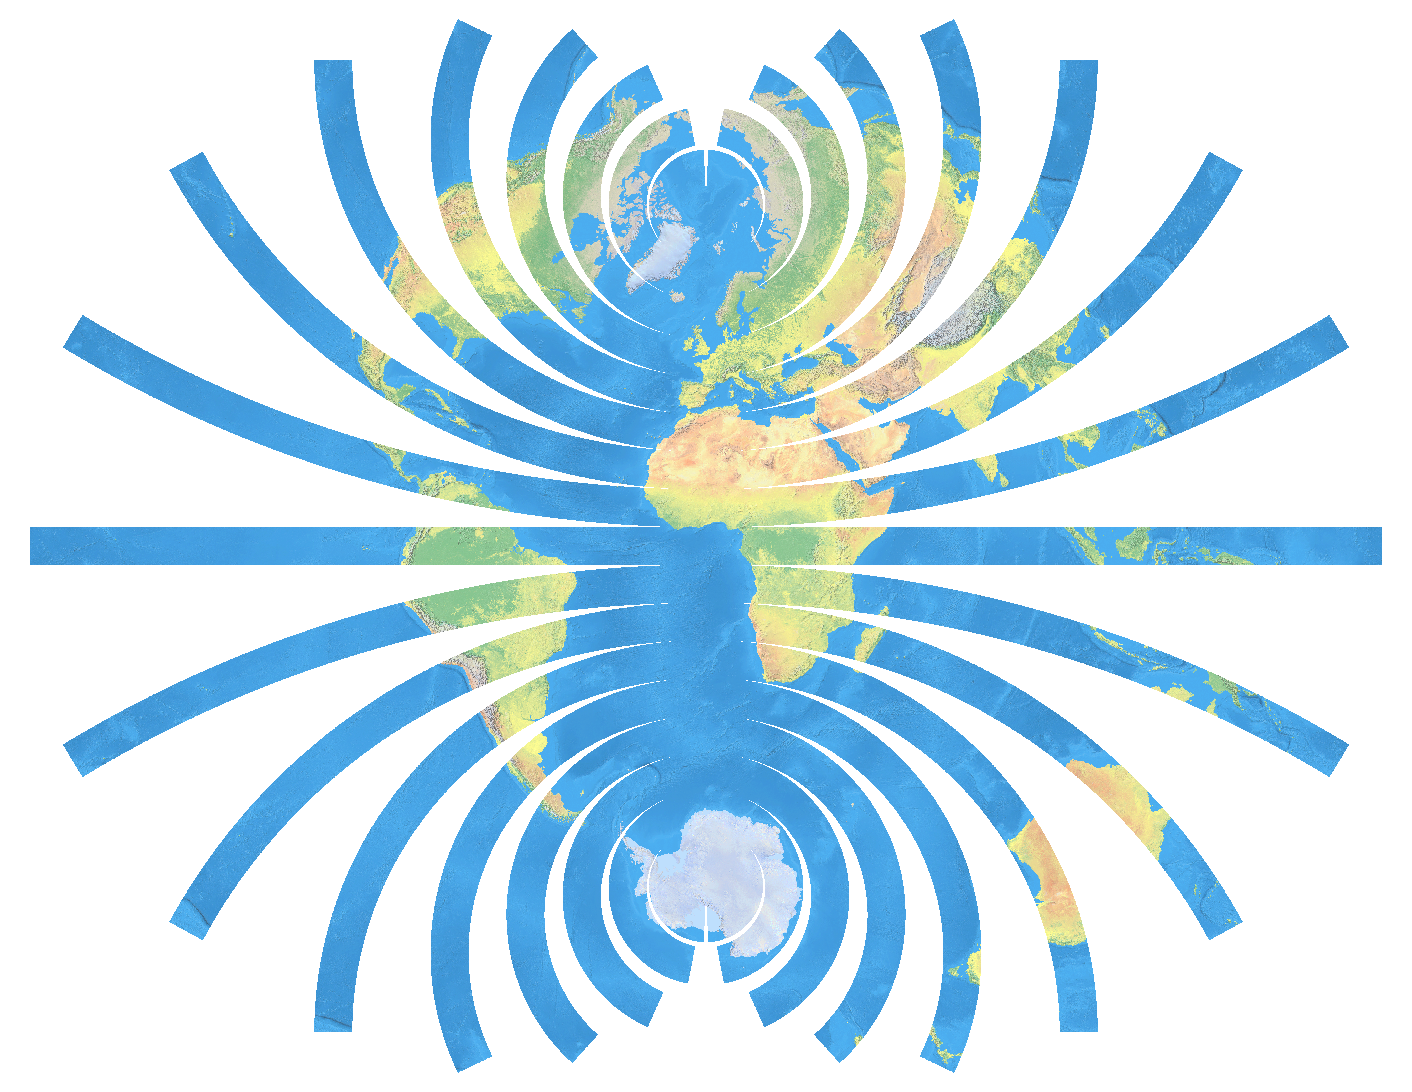

In [32]:
# Interrupted polyconic world map figures

fig_cones = figure(1)
fig_cones.set_figwidth(14./3.)
fig_cones.set_figheight(3.6)
fig_cones.set_dpi(300.)
ax_cones = fig_cones.add_axes((0., 0., 1., 1.))


def plot_flattened(original, jlon, jlat, icone, extent, dj=0, bg="white",
                   save=None):
    if dj:
        # Note that actual width of original is 2160 pixels for -pi to pi
        # so -1080 < dj < 1080 is actual range mapping to -180 < lon < 180
        # or dj = 6 corresponds to a 1 degree rotation
        # dj = -450 lines up the Americas pretty well
        nx = original.shape[1]
        jlon = (jlon + dj) % nx
        if jlon.min() < 0:
            jlon = (jlon + nx) % nx
    flat = original[jlat, jlon]
    flat[icone < 0] = tuple(int(x * 255 + 0.5) for x in to_rgb(bg))
    ax_cones.clear()
    ax_cones.set_aspect("equal", adjustable="box")
    ax_cones.axis("off")
    ax_cones.imshow(flat, extent=extent)
    if save:
        if not isinstance(save, str):
            save = "fig_polycone"
        if dj:
            nx = original.shape[1]
            dj = dj % nx
            if dj < 0:
                dj += nx
            save += "{}".format(dj)
        save += ".png"
        savefig(save, dpi=300, facecolor="w")


def spinning_movie(name="fig_polyspin.mp4"):
    ffmpeg = mwriters["ffmpeg"]
    writer = ffmpeg(fps=48, metadata=dict(title="  ",
        comment="polyconic projection of spinning globe"))
    dpi = 300
    # Write 241 frame 5 second movie of a single rotation.
    with writer.saving(fig_cones, name, dpi):
        for i in range(241):
            plot_flattened(world, *poly_world, dj=2160-9*i)
            writer.grab_frame()


plot_flattened(world, *poly_world, dj=0, save=0)
# spinning_movie()


In [ ]:
from ephemeris import ephemeris

ephemeris.set_model(planets=("mercury", "venus", "earth", "mars"))

In [ ]:
# Figure 3 of paper (called fig1 in this notebook)
# Note that you can call fig1() with increasing values of first argument to
# generate frames of a progressive reveal viewgraph for a presentation.abs
# (See below.)

# nhfig1 caption:
#
# Orbits of the outer planets and New Horizons (NH) viewed from the
# ecliptic north pole.  The dotted line is zero right ascension.  The
# P and W rays show the directions to Proxima Cen and Wolf 359,
# respectively, as measured in NH images on 2020-04-23.  Each ray passes
# through the exact 3D position of its star taken from the Gaia archive,
# so the spacecraft must have been at their intersection point on that
# date.  Proxima Cen is about 45 degrees south of the ecliptic, so the
# P ray is pointing into the page at that angle.  Wolf 359 is nearly in
# the ecliptic plane, and the spacecraft is within 2 degrees.
def fig1(prog=4, save=False, name="nhfig1.png", dpi=300):
    fig_1 = figure(1)
    clf()
    fig_1.set_figwidth(9.77)
    fig_1.set_figheight(7.45)
    fig_1.set_dpi(100.)
    axes(aspect="equal").set_axis_off()
    # axis() -> (-50.768, 69.11, -36.685, 60.451)
    plot(-50.768, 60.451, ".w", ms=0.01)  # force savefig to not crop so all
    plot(69.110, -36.685, ".w", ms=0.01)  # prog values give same png size
    plot(*vernal_up(jup_xyz), c="0.7", lw=1)
    plot(*vernal_up(sat_xyz), c="0.7", lw=1)
    plot(*vernal_up(ura_xyz), c="0.7", lw=1)
    plot(*vernal_up(nep_xyz), c="0.7", lw=1)
    plot(*vernal_up(plu_xyz), c="0.7", lw=1)
    arrow(0, 0, 0, 51, color="0.45", head_width=3, head_length=4.5,
          zorder=2)
    for y in [0, 10, 20, 30, 40, 50]:
        plot([-1.8, 0], [y, y], c="0.45", lw=1)
        text(-2.5, y, str(y), va="center", ha="right", c="0.45", size=10)
    text(1, 48, "x (au)", va="center", ha="left", c="0.45", size=12)
    if prog > 2:
        plot(*nh_ticks, c="k", lw=0.75)
        plot(*nh_xy, c="k", solid_capstyle="round")
        px, py = vernal_up(nh_xyz[:, -1])
        text(px+1, py, "NH", size="large", va="center", ha="left", c="k")
    plot(0, 0, "o", ms=5, c="orange")
    if prog > 3:
        # Note that prox_d and wolf_d do not have vernal_up applied,
        # so they are perpendicular to seg_prox and seg_wolf
        perp = prox_d[:2]
        perp /= sqrt(sum(perp**2))
        xp, yp = perp * rprox * (pi / 180. / 3600.)  # 1 arcsec displacement
        x, y = seg_prox
        plot(x+xp, y+yp, c="#d73027", lw=0.75, dashes=[0.75, 2])
        plot(x-xp, y-yp, c="#d73027", lw=0.75, dashes=[0.75, 2])
        perp = wolf_d[:2]
        perp /= sqrt(sum(perp**2))
        xp, yp = perp * rwolf * (pi / 180. / 3600.)  # 1 arcsec displacement
        x, y = seg_wolf
        plot(x+xp, y+yp, c="#4575b4", lw=0.75, dashes=[0.75, 2])
        plot(x-xp, y-yp, c="#4575b4", lw=0.75, dashes=[0.75, 2])
    if prog > 0:
        plot(*seg_prox, c="#d73027")
        text(35, 22.2, "P", size="large", va="center", ha="center",
             c="#d73027")
        ang = arctan2(*(prox_d[:2]*[1, -1])) * 180./pi
        text(45.1, 2.5, "Proxima Cen", size=10, c="#d73027", rotation=ang)
        c, s = cos(ang * pi/180.), sin(ang * pi/180.)
        arrow(59.8, 2.7, 2.7*c, 2.7*s, width=0.1, head_width=1.2,
              color="#d73027")
    if prog > 1:
        plot(*seg_wolf, c="#4575b4")
        text(46.2, 27, "W", size="large", va="center", ha="center",
             c="#4575b4")
        ang = arctan2(*(wolf_d[:2]*[-1, 1])) * 180./pi
        text(32.9, -27.3, "Wolf 359", size=10, c="#4575b4", rotation=ang)
        c, s = -cos(ang * pi/180.), -sin(ang * pi/180.)
        arrow(33.5, -28, 2.7*c, 2.7*s, width=0.1, head_width=1.2,
              color="#4575b4")
    if prog > 1:
        text(8, 52, "New Horizons 2020-04-23", size=14, c="k")
    axis((-50.768, 69.110, -36.685, None))
    if save:
        if prog < 4:
            name = name.split(".")
            name = ".".join([name[0] + "-{}".format(prog), name[1]])
        savefig(name, dpi=dpi, facecolor="w")


# Lines are skew by about 1/3 AU.
prox_0, wolf_0, pw_skew = closest_pts(prox_p, prox_d, wolf_p, wolf_d)
# distances to proxima and wolf (from SS barycenter)
rprox = sqrt(sum(prox_p**2))
rwolf = sqrt(sum(wolf_p**2))

rot_prox, rot_wolf = uspace_rot(prox_d), uspace_rot(wolf_d)
arrow_prox = arrow_along(prox_q, prox_d, -92, 47)
arrow_wolf = arrow_along(wolf_q, wolf_d, -70, 18)
seg_prox = pts_on_line(prox_q, prox_d, -92, 51.5)
seg_wolf = pts_on_line(wolf_q, wolf_d, -70, 21)
los_dot = array([0., 0.])
prox_line = matmul(rot_prox, (wolf_q + array([[-70.], [21.]])*wolf_d
                              - prox_q)[..., None])[..., 0].T
wolf_line = matmul(rot_wolf, (prox_q + array([[-92.], [51.5]])*prox_d
                              - wolf_q)[..., None])[..., 0].T
prox_nhpos = matmul(rot_prox, nh_xyz - prox_q[:, None])
wolf_nhpos = matmul(rot_wolf, nh_xyz - wolf_q[:, None])

nh_xy = vernal_up(nh_xyz)
nh_ticks = get_ticks(*nh_xy, 1.4)
# 2454102.0 is 2007-01-01 12:00+00:00
tickt = 2454102.0 + 365.25 * arange(17)
ticki = interp(tickt, jpl_nh_jd, arange(jpl_nh_jd.size))
tickf = ticki % 1.0
ticki = (ticki // 1.0).astype(int)
nh_ticks = (1. - tickf)*nh_ticks[..., ticki] + tickf*nh_ticks[..., ticki+1]

# fig1(0)
# fig1(1)
# fig1(2)
# fig1(3)
# fig1(4)
# Use "Save As" button in plot to save the plot as png file.
fig1()

In [ ]:
# Figure 4 of paper (called fig2 in this notebook)

# Note that the two ticks on either side of April 23 are April 6 and May 6.
# Distance from x6 to 0.5*(nh_prox + nh_wolf) is 0.35 au.
#   0.082 arcsec from Proxima line and 0.144 arcsec from Wolf line
#   (0.020 pixels from Proxima line and 0.035 pixels from Wolf line)
# Assuming sigma_d = 1 microrad for each individual image, or 0.408 microrad
#   for 6 aggregated images, the chi2 for the final fit is 26.4 for the
#   12 line fit (21 degrees of freedom, 13.2-29.6 is 0.9-0.1),
#   or 0.32 for the 2 line fit (1 degree of freedom, 0.016-2.71 is 0.9-0.1).
#   The fits are behaving exactly as expected.
# For 6 aggregated images, actual  NH position 0.5*(nh_prox + nh_wolf)
#   has chi2 = 4.2 for the 2 line fit (between 0.05 and 0.025 in chi2 distrib)
#   or chi2 = 30.2 for the 12 line fit (between 0.1 and 0.05, near 0.1)
#
# With sigma_a = 0.44 arcsec per image,
# nhmx6 = 0.5*(nh_prox+nh_wolf), x6inv = inv(x6cov)
# actual position is nhmx6.dot(x6inv.dot(nhmx6))/sigma_a**2 = 0.9231 sigma
def fig2(save=False, name="nhfig2.png", dpi=300,
         sigma_a=0.44):
    if not fignum_exists(2):
        fig_2 = figure(2, layout=None)
    else:
        fig_2 = figure(2)
    fig_2.set_figwidth(10)
    fig_2.set_figheight(5)
    fig_2.set_dpi(100.)
    fig_2.clear()
    sigma_a = sigma_a * pi/180./3600.
    gs = fig_2.add_gridspec(nrows=1, ncols=2, left=0.025, right=0.975,
                            top=0.95, bottom=0.05, hspace=0.05, wspace=0.1)
    ax0, ax1 = fig_2.add_subplot(gs[0, 0]), fig_2.add_subplot(gs[0, 1])
    for ax in ax0, ax1:
        ax.clear()
        ax.set_aspect("equal")
        ax.set_axis_off()
    # point to zoom around in ax0: (0, 0), in ax1: (-0.2, 0)
    ax0.axis([-0.30, 0.30, -0.30, 0.30])
    ax1.axis([-0.50, 0.10, -0.30, 0.30])
    for r, n, rot, q, d, _0, line, c1, c2, ax in [
            [rprox, 8, rot_prox, prox_q, prox_d, wolf_0, prox_line,
             "#d73027", "#4575b4", ax0],
            [rwolf, 5, rot_wolf, wolf_q, wolf_d, prox_0, wolf_line,
             "#4575b4", "#d73027", ax1]]:
        is_ax0 = r < 300000.0
        # axes
        xy = matmul(rot, nh_xyz[:, 169:183]-q[:, None])
        ticks = get_ticks(*xy, 0.03)
        xytk = (asfarray(ticks)[:, :, 7] - asfarray(xy)[:, None, 7]) * 1.6
        x0, y0 = matmul(rot, 0.5*(nh_prox + nh_wolf) - q)
        # ax.arrow(x0, y0, 0,0.54, width=0.002, head_width=0.040, color="0.75")
        ax.plot([x0, x0], [y0-0.5, y0+0.5], c="0.75", lw=2)
        for tick in arange(-3, 3):
            tick = 0.1 * (tick if is_ax0 else tick + 1)
            if tick == 0.0:
                continue
            ax.plot([x0-0.01, x0+0.01], [y0+tick, y0+tick], c="0.75", lw=2)
            ax.text(x0-0.02, y0+tick, "{:4.1f}".format(tick),
                    c="0.75", size=10, va="center", ha="right")
        ax.text(x0-0.02, y0+(0.15 if is_ax0 else 0.35), "(au)",
                c="0.75", size=10, va="center", ha="right")
        # ax.arrow(x0, y0,-0.54,0, width=0.002, head_width=0.040, color="0.75")
        ax.plot([x0-0.5, x0+0.5], [y0, y0], c="0.75", lw=2)
        for tick in 0.1*arange(-4, 5):
            if tick == 0.0:
                continue
            ax.plot([x0+tick, x0+tick], [y0-0.01, y0+0.01], c="0.75", lw=2)
        # arcsec circles and lines
        arcsec = r * pi / 180. / 3600
        for rr in arange(1, n) * 0.1 * arcsec:
            ax.plot(*circle_pts(0., 0., rr), c=c1, lw=1, dashes=[1, 2.6])
        x, y = line
        dx, dy = y[0] - y[1], x[1] - x[0]
        rr = sqrt(dx**2 + dy**2)
        dx, dy = dx/rr, dy/rr
        arcsec = (rprox + rwolf - r) * pi / 180. / 3600
        for rr in arange(n-13, 13-n) * 0.1 * arcsec:
            if rr:
                ax.plot(x+rr*dx, y+rr*dy, c=c2, lw=1, dashes=[1, 2.6])
        # NH trajectory (right to left in both views)
        # Ticks are exactly 30 days apart at 00:00:00 UTC
        # 2020-02-06, 2020-03-07, 2020-04-06, 2020-05-06, 2020-06-05
        nh = array([x0, y0])
        ax.plot(*ticks, c="k", lw=0.75)
        ax.plot(*xy, c="k")
        # ax.plot(*(xytk + nh[:, None]), c="k")
        ax.plot(*nh, "o", ms=8, c="k")
        # gray dashed shortest distance line between P and W
        p0, p1 = los_dot, matmul(rot, _0-q)
        ax.plot([p0[0], p1[0]], [p0[1], p1[1]], "--", c="0.5")
        kaplan = 0.5*(p0 + p1)
        ax.plot(*kaplan, marker="o", ms=5, c="0.5")  # dot at midpoint
        weighted = matmul(rot, x6-q)  # wxyz-q
        ax.plot(*weighted, marker="*", ms=16, c="k")
        ax.plot(*ellipsoid(*weighted, rot, x6cov, sigma_a), c="k")
        ax.plot(*ellipsoid(*weighted, rot, x6cov, 0.5*sigma_a), c="k",
                lw=1, dashes=[6, 4])
        ax.plot(*ellipsoid(*weighted, rot, x6cov, 1.5*sigma_a), c="k",
                lw=1, dashes=[6, 4])
        # P and W themselves with dots at closest approach
        ax.plot(*p0, "o", ms=5, c=c1)
        ax.plot(*line, c=c2)
        ax.plot(*p1, "o", ms=5, c=c2)
        # annotations
        p0 = matmul(rot, _0 - q)
        p1 = line[:, 1] - line[:, 0]
        p1 /= sqrt(sum(p1**2)) * 40
        if is_ax0:  # this is proxima subplot
            ax.text(-0.28, 0.22, "NH", size="large", c="k")
            # ax.text(0.020, -0.022, "P", size="large", c=c1)
            ax.text(0.008, -0.01, "P", size="large", c=c1)
            ax.text(0.03, -0.16, "W", size="large", c=c2)
            p0 += [0.045, -0.014]
        else:  # this is wolf subplot
            ax.text(-0.49, -0.075, "NH", size="large", c="k")
            ax.text(0.01, -0.012, "W", size="large", c=c1)
            ax.text(-0.113, 0.092, "P", size="large", c=c2)
            p0 += [-0.025, 0.003]
        ax.arrow(*p0, *p1, width=0.0007, head_width=0.0084, color=c2)
    if save:
        savefig(name, dpi=dpi, facecolor="w")


fig2()  # Use "Save As" button in plot to save as png file